# AIR Homework 2 (Task 1)

## Setup

This notebook covers Task 1. If you haven't already, read `start_here.ipynb` first. It has the assignment overview, the submission instructions, and how to set up the conda environment.

Run the cells below before you start. They set up the notebook, load our working environment from `scene.py`, and import your code from `task1.py`.

In [ ]:
%load_ext autoreload
%autoreload 2

# Set the EGL backend for MuJoCo on Linux (no effect on other operating systems)
import platform

if platform.system() == "Linux":
  %env MUJOCO_GL=egl

In [ ]:
# load our working environment from scene.py (see start_here.ipynb). load_scene replaces the
# model and the data, so we always read them through the module, e.g. scene.data.time
import scene
from scene import render, reset, set_seed, show_video

import time

import mediapy as media
import numpy as np

np.set_printoptions(precision=3, suppress=True)  # print numbers with 3 decimals
from unified_planning.io import PDDLReader
from unified_planning.shortcuts import OneshotPlanner, SequentialSimulator

In [ ]:
# import your code for this task. the rest of this notebook calls it through the
# module, e.g. t1.execute_with_monitoring
import task1 as t1

## Task 1: Closing the Loop

In the TAMP tutorial we put our tools together in the simplest arrangement there is: the task planner plans, *then* the robot executes the plan one action at a time, with a motion plan for each. This is task planning *then* motion planning, or **decoupled task and motion planning**, and it gets us surprisingly far. We also saw that the execution of a plan can fail, and that a robot that compares the world with what it expected can notice this and replan.

In this task we take a closer look at how plans fail during execution, and at what replanning can and cannot fix. We will:

* meet our decoupled system again, in a world with a wall and a window, and see what a plan does and does not say about how the robot should move,
* make the **sampler** of `put-down` aware of the arm's reach,
* execute plans **open loop**, and see three very different ways in which they fail,
* **close the loop**: check the abstract state after every action against the state that the task planner expects, and **replan** when the world disagrees with the plan,
* solve a long-horizon task end to end, with an adversary getting in the way,
* and find the failures that replanning cannot fix, which we address in Task 2.

### Where we left off

Let's review the components we have, and the functions that implement them in `scene.py` and `task1.py`:

| component | what it does | our tools |
|---|---|---|
| Task planning | from a PDDL problem to a sequence of actions | `OneshotPlanner` |
| Inverse kinematics | from a tool pose to joint angles | `scene.analytical_ik`, `scene.choose_solution` |
| Motion planning | from one configuration to another, around obstacles | `scene.plan`, `scene.follow_path`, `scene.go_to` |
| Control | tracking a target configuration | the servos in the actuators |
| State estimation | from the world to the facts of the task planner | `t1.estimate_state`, `t1.true_state` |

The first row lives in a world of *symbols*: blocks, tables, `(on b2 b1)`. The other rows live in a world of *numbers*: joint angles, positions, contact forces. A robot needs both, and the two have to be connected.

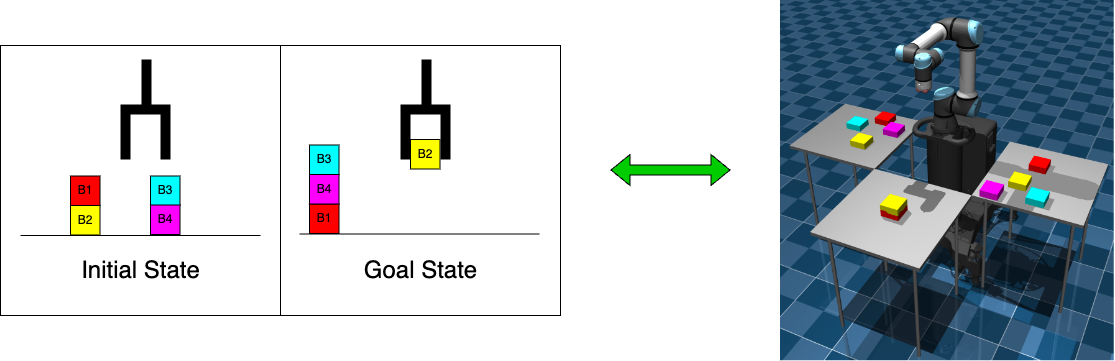

We start with the N-Table Blocks World domain of the TAMP tutorial, and the problem instance that our simulated scene was modeled after.

`NTBW_DOMAIN` is provided in `task1.py`.

In [ ]:
NTBW_PROBLEM = """
(define (problem ntbw-3t5b)
  (:domain n-table-blocks-world)
  (:objects
    b1 b2 b3 b4 b5 - block
    yellow blue green red - color
    t1 t2 t3 - table)
  (:init
    (handempty)
    (ontable b1 t1) (bcolor b1 yellow)
    (on b2 b1) (clear b2) (bcolor b2 blue)
    (ontable b3 t2) (clear b3) (bcolor b3 yellow)
    (ontable b4 t3) (clear b4) (bcolor b4 green)
    (ontable b5 t3) (clear b5) (bcolor b5 red))
  (:goal (and (on b3 b1)))
)
"""

problem = PDDLReader().parse_problem_string(t1.NTBW_DOMAIN, NTBW_PROBLEM)

with OneshotPlanner(name="fast-downward") as planner:
    task_plan = list(planner.solve(problem).plan.actions)

print("the plan:")
for i, action in enumerate(task_plan):
    print(f"  {i + 1}. {action}")

reset()
media.show_image(render())

The plan has four actions, but the robot does not yet know how to execute them. ❓ **Read the plan as if you were the robot.** `unstack(b2, b1)`: how high above `b2` should the tool arrive, and from which side? `put-down(b2, t1)`: *where* on `t1`, a table sixty centimeters wide, behind a wall? `stack(b3, b1)`: what if `b1` has moved a little since the plan was made? The plan does not say any of this, and this is on purpose, since leaving out these details is what makes the planning problem small enough to solve. It is up to us to fill them in.

### Two worlds, two mappings

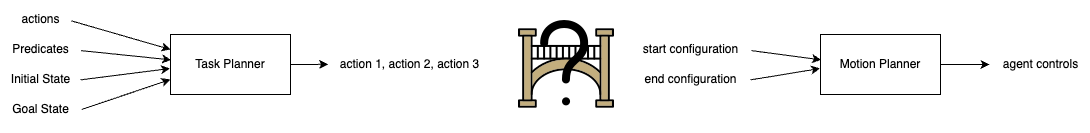

The task planner speaks in **objects**, **facts** and **actions**. The motion planner speaks in **configurations**. Bridging them takes two mappings, one in each direction:

* from the world to the facts: which facts hold, given where everything is? This is the **state estimator**, the symbolic grounder of the TAMP tutorial. We need it before planning (is the initial state of the problem the actual state of the world?), after every action (did the action do what the plan says?) and at the end (is the goal really achieved?).
* from an action to motions: which configurations must the robot go through, and what must the gripper do, so that the effects of the action come true? We will call the implementation of one action a **skill**.

There is one more mapping, which is trivial here and easy to miss, between the *names*. The planner's `b2` must be the simulator's `b2`. We built our scene from the PDDL problem, so the names coincide; on a real robot this is a table that somebody has to write and maintain (this block is `b2`, that table is `t1`), or a matter of tracking which detected object is which.

#### The state estimator

As in the TAMP tutorial, we read the *true* state from the simulator's contacts (a block is on whatever pushes it up). On a real robot, perception would have to estimate it, but state estimation is not our topic here. Facts are tuples: `("on", "b2", "b1")`, `("handempty",)`.

Note that a block released a centimeter above the table bounces for a moment, and during that moment it touches nothing. `estimate_state` lets the simulation settle before reading the contacts.

`true_state`, `settle`, `estimate_state`, `fact_string` and `print_state` are provided in `task1.py`.

In [ ]:
reset()
t1.print_state(t1.estimate_state())

#### Facts in and out of the planner

The planner has its own representation of a state, and we need to convert in both directions: from a planner state to our tuples (to know what the planner *expects*), and from our tuples to a planning problem (to plan from the state the robot actually finds itself in). The second direction is easiest done by writing PDDL. The colors never change, so we add them to every problem we write.

`facts_of`, `goal_facts`, `goal_holds`, `make_problem` and `solve` are provided in `task1.py`. `make_problem(facts, goal, domain, numbers)` can write a problem for any domain, and can also write numbers into it (for action costs), which we will need in Task 2. `goal_holds(problem)` checks whether the goal of a problem holds in its initial state, for goals of any form.

In [ ]:
GOAL = "(and (on b3 b1))"

with SequentialSimulator(problem) as simulator:
    initial_facts = t1.facts_of(simulator.get_initial_state(), problem)
print("the PDDL problem and the simulation agree on the initial state:", initial_facts == t1.estimate_state())
print("the plan from the estimated state:", t1.solve(t1.make_problem(t1.estimate_state(), GOAL)))

(We asked for `fast-downward-opt`, the optimal configuration of Fast Downward, rather than the satisficing one we used above; we will see why in a moment.)

Plans are lists of *action instances*. Each has a name and parameters, which is all a skill needs to know:

In [ ]:
action = task_plan[1]
print("action:", action, " name:", action.action.name, " parameters:", [str(p) for p in action.actual_parameters])

### Skills: from actions to motions

A skill is a piece of code that makes the effects of an action come true in the world, and it uses all the robotics we have seen so far: inverse kinematics, motion planning and control. Take `pick-up`. What does it require of the arm? Three motions and a gripper command:

1. **approach**: bring the tool to a point *above* the block, a safe height away. This is the long motion, possibly around obstacles, so it goes through the motion planner.
2. **descend**: go straight down until the suction cup touches the block. This is a short motion, and we want it to be *straight*, because the planner does not know that a cup must arrive from above.
3. **grasp**: switch on the suction.
4. **lift**: straight back up, now with the block.

We wrote skills like this one in the TAMP tutorial. Here they are again (`pick_up`, and its mirror image for putting a block down, `place`), with two improvements that become necessary when the robot executes long plans.

The first is about *which* inverse kinematics solution to use. Until now we chose the solution closest to where the robot was, for the approach pose first and then for the grasp pose, and it worked. But the two poses are a hand's width apart, and it can happen that the family of solutions that reaches the approach pose comfortably cannot reach the grasp pose at all (a link touches the window's lintel on the way down, say). Then the grasp pose gets a solution from *another* family, the "straight" descent turns into a wild swing of the whole arm, and things get knocked over. The fix is to plan the grasp **backwards**: choose the grasp configuration first (it is the constrained one), and then the approach configuration *in the same family*, as close to it as possible. `approach_configurations` does this, trying the candidate grasp configurations in order of distance from where the robot is.

The second improvement is that a skill must **report failure** and stop, instead of carrying on. If the approach fails, we do not descend; if the descent is blocked, we do not release the block. Every skill returns whether it succeeded, and the video frames of what it did.

`approach_configurations`, `pick_configurations`, `place_configurations`, `pick_up`, `place` and `stack` are provided in `task1.py`.

In [ ]:
set_seed(42)
reset()
success, frames = t1.pick_up("b2")
print("success:", success)
t1.print_state(t1.estimate_state())
show_video(frames)

The state now contains `(holding b2)`, so the skill made the effect of `unstack(b2, b1)` come true. ❓ **Which parameters did it use?** `pick_up` takes only the block: the table in `pick-up(b3, t2)` and the lower block in `unstack(b2, b1)` are needed by the *planner*, to keep its facts straight, but the robot finds the block by its position, wherever it is. `stack(b3, b1)` needs the position of `b1`, which the skill looks up at execution time, not when the plan was made. Finally, `put-down(b2, t1)` needs a position on `t1`, but which one?

#### Where to put a block down: sampling

This is where the abstraction leaves out something the robot needs. `(ontable b2 t1)` is one fact, but there are infinitely many arrangements of the world in which it holds: `b2` anywhere on the table, and every other block anywhere at all. The task planner does not care which; the robot has to pick one. The state estimator is the mapping from world states to facts; what we need now is its **inverse**. Since the mapping is many-to-one, inverting it requires making a *choice*. In task and motion planning this component is called the **state sampler** (or grounding sampler): given the fact to achieve, produce a concrete state of the world that achieves it.

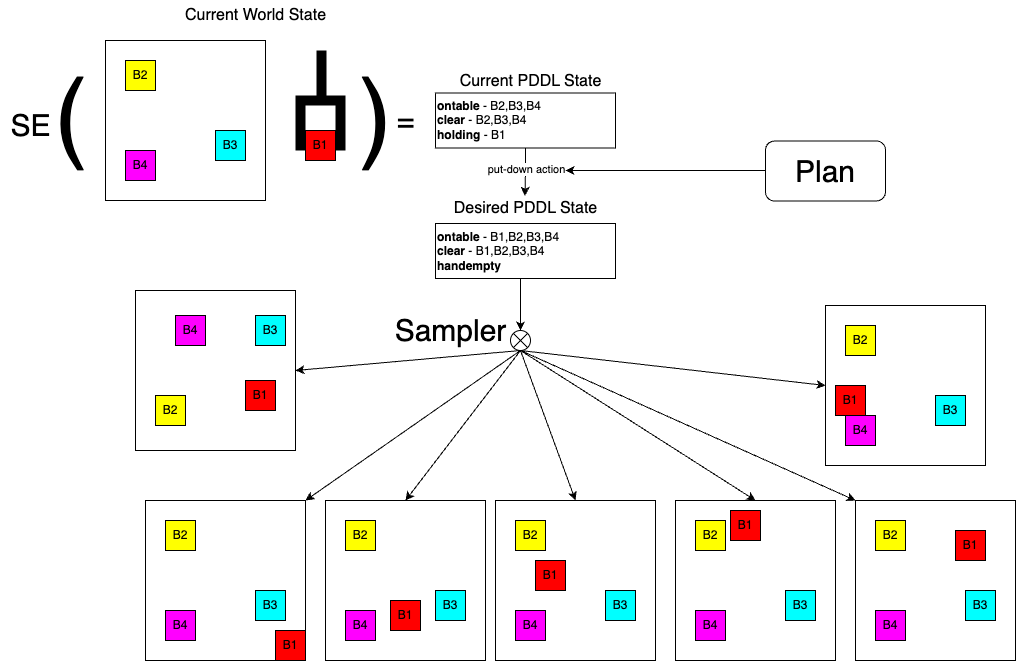

The figure shows why the sampler cannot be as generic as the estimator. All seven samples satisfy the desired facts, but six of them move blocks that the action never mentioned. We want the sample that changes *only what the action changes*: `b2` on the table, everything else where it is. For `put-down`, the sampler only needs to choose a position $(x, y)$ on the table, and the position must be

* **on the table**, with the whole block on it, not just its center,
* **free**: not overlapping any block that is already there,
* **reachable**: the arm must be able to get the block there and let go,
* and, ideally, not in the way of what comes next (this last one we will come back to).

The standard approach, sampling-based like our motion planners, is **rejection sampling**: draw a random position, test the conditions, and draw again until they all hold. The geometry of the tables and blocks is part of the robot's knowledge of its workspace, and we read it from the model.

`table_surface` and `table_point` are provided in `task1.py`.

In [ ]:
for table in scene.TABLES:
    height, center, half_size = t1.table_surface(table)
    print(f"{table}: top face at z = {height:.2f} m, centered at {center}, half extents {half_size}")

`sample_on_table(table)` returns a uniformly random $(x, y)$ on the top of the table, far enough from the edges for a block centered there to sit fully on it. `is_free(xy, exclude)` is `True` if a block put down at `xy` would overlap none of the blocks currently on the tables, with a margin of `MARGIN` around each (two blocks overlap if their centers are closer than a block width along *both* axes). `exclude` is a block to ignore: the one the robot is holding. The cell below draws a map of the tables with a hundred samples, green if free and red if not.

`MARGIN`, `sample_on_table`, `is_free` and `draw_map` are provided in `task1.py`.

In [ ]:
reset()
np.random.seed(0)
spots = [t1.sample_on_table(table) for table in scene.TABLES for _ in range(35)]
t1.draw_map(spots, ["green" if t1.is_free(xy) else "red" for xy in spots], "random spots on the tables: free (green) or not (red)")

Now reachability. Whether the arm can put a block down at a spot is a question for the *motion* layer: is there a collision-free configuration for the release pose, and one for hovering above it, in the same family? This is what `approach_configurations` computes, so the sampler can simply call it. We add one more piece of workspace knowledge: the UR5e reaches about 85 cm from its base, and a spot at the very edge of its reach is a bad place for a block, because reaching *over* it, to stack something on top or to pick it up again from another side, is then impossible. We keep spots within 80 cm.

Implement `is_reachable(table, xy)`, which returns whether the robot can put a block down at the spot $(x, y)$ on the table: the spot must be within `MAX_REACH` of the robot's base, which is at the origin of the world, and there must be configurations for placing a block on it (see `place_configurations` and `table_point`).

**TODO:** implement `is_reachable` in `task1.py`. `MAX_REACH` is provided there.

From here on, cells that start with `# sanity check` run a few quick checks on what you just implemented, and print what they found. If one fails, something is wrong. If it passes, you are heading in the right direction, but your code may still have bugs: these checks are not the tests we will run on your submission.

In [ ]:
import unittest

test = unittest.TestCase()  # used by the sanity checks

In [ ]:
# sanity check: is_reachable
reset()

# well within reach, on the tables in front of the robot and on its left, and through the window
test.assertTrue(t1.is_reachable("t2", np.array([0.5, 0.0])), "(0.5, 0) on t2 should be reachable")
test.assertTrue(t1.is_reachable("t3", np.array([0.0, 0.55])), "(0, 0.55) on t3 should be reachable")
test.assertTrue(t1.is_reachable("t1", np.array([-0.18, -0.59])), "(-0.18, -0.59) on t1 should be reachable")

# right behind the wall: the arm cannot get low enough there through the window
test.assertFalse(t1.is_reachable("t1", np.array([-0.14, -0.39])), "(-0.14, -0.39) on t1 is too close to the wall")

# the arm can get to the far corner of t1, but it is beyond MAX_REACH
test.assertFalse(t1.is_reachable("t1", np.array([-0.22, -0.83])), "(-0.22, -0.83) on t1 is beyond MAX_REACH")

# the result is a boolean, so that the sampler can use it in a condition
test.assertIn(t1.is_reachable("t2", np.array([0.5, 0.0])), [True, False])

print("is_reachable sanity checks passed.")

The map below tests every spot on a grid. ❓ **Before you run it, guess where the unreachable spots are.**

In [ ]:
reset()
grid = [(table, center + [dx, dy]) for table in scene.TABLES for _, center, _ in [t1.table_surface(table)]
        for dx in np.linspace(-0.26, 0.26, 12) for dy in np.linspace(-0.26, 0.26, 12)]
t1.draw_map([xy for _, xy in grid], ["green" if t1.is_reachable(table, xy) else "red" for table, xy in grid], "reachable (green) and unreachable (red) spots")

The far edges of all three tables are beyond our reach limit, and on `t1` the strip right behind the wall is out too: the arm cannot get low enough there without touching the sill or the lintel. (A few spots are red only because a block is already there.) None of this is in the PDDL model, and it should not be. This kind of knowledge belongs in the motion layer, and the sampler consults it on the task planner's behalf.

`sample_free_spot` puts the three tests together, and gives up after a number of attempts, since on a crowded table there may be no free spot at all, and the skill must be able to report that.

`sample_free_spot` and `put_down` are provided in `task1.py`.

In [ ]:
np.random.seed(1)
print("a spot for b2 on t1:", t1.sample_free_spot("t1", "b2"))

#### From an action instance to a skill

`execute_action(action, sampler)` runs the skill that implements one action instance of the plan, and returns what the skill returns, `(success, frames)`. It reads the action's name and its parameters (as strings), and dispatches: `pick-up` and `unstack` both call `pick_up` with the block; `stack` calls `stack`; `put-down` asks the `sampler` for a spot on the table (and fails, with a message, if it returns `None`) and calls `put_down`. The cell below executes the first two actions of the plan and prints the state.

`execute_action` is provided in `task1.py`.

In [ ]:
set_seed(42)
reset()
for action in task_plan[:2]:
    success, frames = t1.execute_action(action)
    print(f"{action}: {'ok' if success else 'FAILED'}")
t1.print_state(t1.estimate_state())

### Executing a plan

`execute_plan(task_plan, sampler, after_action)` executes the actions one after the other, collecting the frames, and stops at the first action whose skill fails. It returns `(success, frames)`, and writes the action being executed at the top of the video. We will get to `after_action` later. Let's run the plan from the initial state, watch it, and check whether the goal holds at the end (the goal is a set of facts, and it holds if it is a subset of the estimated state).

`caption` and `execute_plan` are provided in `task1.py`.

In [ ]:
set_seed(42)
reset()
success, frames = t1.execute_plan(task_plan)
print("all skills succeeded:", success)
print("goal achieved:", t1.goal_facts(problem) <= t1.estimate_state())
show_video(frames)

This is all there is to decoupled task and motion planning: plan, then execute each action with a skill. It required a task planner, an inverse kinematics solver, a motion planner, a controller, a state estimator and a sampler.

#### A longer task

Our plan is four actions long. Let's give the robot a bigger task: a tower of all five blocks on `t2`, in order. This is where the choice of planner starts to matter. Compare the plans of the two configurations of Fast Downward:

In [ ]:
TOWER_GOAL = "(and (ontable b1 t2) (on b2 b1) (on b3 b2) (on b4 b3) (on b5 b4))"

reset()
tower_problem = t1.make_problem(t1.estimate_state(), TOWER_GOAL)
for name in ["fast-downward", "fast-downward-opt"]:
    with OneshotPlanner(name=name) as planner:
        actions = planner.solve(tower_problem).plan.actions
    print(f"{name}: {len(actions)} actions:", ", ".join(map(str, actions)))

❓ **Why did we not care about this in the task planning tutorial?** There, an action was a line of text, and a plan twice as long was only less elegant. Here, every action takes about ten seconds of robot motion and is another chance for something to go wrong, so a plan twice as long takes twice as long to execute and is more likely to fail. We use the optimal planner from now on (our `solve` already does).

Look at the optimal plan too: to free `b1`, the planner parks `b2` on `t1`, behind the wall, where every motion is slow and awkward, when the tables next to the robot are just as good. The planner counts actions, and to it all tables are alike. We will come back to this in Task 2.

Now let's run it. The video shows the two minutes of the robot's work at six times real time.

In [ ]:
tower_plan = t1.solve(tower_problem)

set_seed(42)
reset()
success, frames = t1.execute_plan(tower_plan)
print("all skills succeeded:", success)
print("goal achieved:", t1.goal_facts(tower_problem) <= t1.estimate_state())
show_video(frames[::2])  # six times real time

### When things go wrong

A plan that runs open loop, without anyone checking the result, works only as long as nothing goes wrong. There are three very different ways for it to fail.

#### The skill knows it failed

The first kind is a skill that cannot do its job and says so: there is no free spot on the table, the target cannot be reached, the motion planner finds no path, or the suction did not catch. Our executor stops when this happens, which is the right thing to do open loop, since carrying on after a failed `put-down` would mean stacking a block that is still in the gripper.

Let's provoke one. A *naive* sampler that skips the free-spot and reachability tests will sooner or later propose a spot on top of another block, or one the arm cannot reach:

`freeze` and `naive_sampler` are provided in `task1.py`. `freeze` adds a still shot of the scene, with a caption, to a video. `naive_sampler` records the spots it proposes in `t1.proposals`.

In [ ]:
t1.proposals.clear()
set_seed(14)
reset()
success, frames = t1.execute_plan(task_plan, sampler=t1.naive_sampler)
print("all skills succeeded:", success)
t1.print_state(t1.estimate_state())
t1.draw_map(t1.proposals[-1:], ["red"], title="where the plan stopped: b2 is in the gripper,\nthe red dot is where the sampler wanted it")
show_video(frames + t1.freeze("put-down(b2, t1) FAILED: cannot reach the target"))

The skill refused, because there is no collision-free configuration for releasing `b2` at the spot the sampler proposed (the red dot on the map). It is right behind the wall, in the strip of `t1` that the arm cannot get to through the window, and too close to `b1` besides. The video ends with the arm hovering where it picked `b2` up. The skill checks before it moves, so a refusal costs no motion, and the robot keeps holding the block instead of dropping it. The plan stops with `(holding b2)`. As we will see, a failure like this one is easy to recover from, since the state is consistent and a new sample would probably work.

#### The skill thinks it succeeded

The second kind is worse. The skill reports success, but it is wrong. Look at what our skills check: the target is reachable, a path was found, the arm arrived, the grasp caught. These are all about the robot's own *motion*. `place` then lets go and backs off, and never looks at where the block ended up. Most of the time there is nothing to see. But suppose the sampler has a bug, a single wrong sign, so that instead of keeping the center of the block half a block *inside* the edges of the table, it allows it half a block *outside*. Such a spot can be free and reachable, so nothing will stop the skill.

To see the effect of this bug, we ask for a little more than before: `b3` on `b1` as before, and the red block `b5` on `t2`, in front of the robot.

`careless_sampler` is provided in `task1.py`. It records the spots it proposes in `t1.edge_spots`.

In [ ]:
EDGE_GOAL = "(and (on b3 b1) (ontable b5 t2))"

t1.edge_spots.clear()
set_seed(2)
reset()
edge_problem = t1.make_problem(t1.estimate_state(), EDGE_GOAL)
edge_plan = t1.solve(edge_problem)
success, frames = t1.execute_plan(edge_plan, sampler=t1.careless_sampler)
print("all skills succeeded:", success)
print("goal achieved:", t1.goal_facts(edge_problem) <= t1.estimate_state())
print("goal facts that do not hold:", " ".join(t1.fact_string(fact) for fact in sorted(t1.goal_facts(edge_problem) - t1.estimate_state())))
t1.print_state(t1.estimate_state())
t1.draw_map(t1.edge_spots[:1], ["black"], title="the black dot is where the sampler wanted b5")
show_video(frames + t1.freeze("every skill reported success, and b5 is on the floor", seconds=3))

All six actions printed `ok`, and `all skills succeeded: True`, but `b5` is on the floor. The spot (the black dot) was just beyond the edge of `t2`. The arm went there, let go of the block and left without any problem, and then the block tipped over the edge. `put-down(b5, t2)` *failed*: its effect, `(ontable b5 t2)`, never became true. The skill said `ok` because it judges its motion and not its effect, and the robot carried on with the other four actions as if nothing had happened. We know that something went wrong only because we checked the goal ourselves at the end.

We could fix the sign, and we could have `place` verify where the block is after letting go; one should do both. But a skill can only check for the failures its author thought of, and in the real world there are many others: blocks slip, stacks topple and suction cups leak.

#### Somebody else changes the world

In the third kind, nothing fails. Every skill does its job correctly, but the world is nevertheless not what the plan assumes, because something happened that the plan did not model. In our case, somebody else is in the workspace: an adversary. While the robot builds the tower of the previous section, right after it puts `b1` down on `t2` (the fourth action), they move the block to `t3`. (In simulation the adversary can simply teleport the block; a real one would use their hands.)

In the video, the name of the action being executed is written at the top, and the picture stops for a moment when the adversary steps in. Watch what the robot does next, and count the failures in the printout.

`move_block`, `adversary_moves` and `tower_adversary` are provided in `task1.py`. `execute_plan` calls `after_action(step)` after every action, with the number of actions executed so far, and adds the frames it returns to the video. This is how our adversary gets its turn.

In [ ]:
set_seed(42)
reset()
success, frames = t1.execute_plan(tower_plan, after_action=t1.tower_adversary)
print("all skills succeeded:", success)
print("goal achieved:", t1.goal_facts(tower_problem) <= t1.estimate_state())
print("goal facts that do not hold:", " ".join(t1.fact_string(fact) for fact in sorted(t1.goal_facts(tower_problem) - t1.estimate_state())))
t1.print_state(t1.estimate_state())
frames += t1.freeze("every skill reported success, and the tower is on t3 instead of t2", seconds=4)
show_video(frames[::2])  # six times real time

Read the printout again. All twelve actions printed `ok` and `all skills succeeded: True`, but the goal is not achieved. This time, no skill actually failed. `stack(b2, b1)` tells the skill to put `b2` on `b1`, and the skill did that, at the position where it found `b1`; so did the three stacks after it. Each skill checked what it is responsible for (the target is reachable, the grasp caught, the block was let go) and each was right to say that it succeeded. The *plan* stopped being valid after its fourth action, when `(ontable b1 t2)` ceased to be true, and the robot went on for eight more actions, building a correct tower on the wrong table. In open-loop execution, nothing is responsible for noticing this, and we only know because we checked the goal ourselves at the end.

Whether a change that the plan did not model shows up as a refusal, as a silent wrong result, or not at all is a matter of luck. Had the adversary put a block on top of `b1` instead, the next `stack` would have found it in the way and refused, which is a failure of the first kind, detected but late. Had they moved `b1` to another spot on `t2`, the goal would have been achieved all the same.

The second and third kinds have one thing in common. No skill reported a failure, and the plan ran to its end even though it no longer matched the world.

❓ **How can the robot notice earlier?** It has a state estimator. After every action, the estimator can tell what *is*, and the planner can tell what *should be*: the state that results from applying the action to the previous one, which is what the sequential simulator of the TAMP tutorial computes. If the two disagree, the plan is no longer valid, and the robot should stop and replan.

Implement `expected_states(problem, task_plan)`, which returns a list with the set of facts that the planner expects after each action of the plan. Use a `SequentialSimulator` for the problem, as in the replanning loop of the TAMP tutorial (`simulator.get_initial_state()`, `simulator.apply(state, action)`), and `facts_of` to turn each of its states into a set of facts.

**TODO:** implement `expected_states` in `task1.py`.

In [ ]:
for action, facts in zip(task_plan, t1.expected_states(problem, task_plan)):
    print(f"after {action}:")
    t1.print_state(facts)

In [ ]:
# sanity check: expected_states
states = t1.expected_states(problem, task_plan)
test.assertEqual(len(states), len(task_plan), "there should be one state per action of the plan, and none for the initial state")
test.assertTrue(all(isinstance(facts, set) for facts in states), "each state should be a set of facts")

# after the first action, unstack(b2, b1), the robot holds b2 and b1 is clear
test.assertEqual(str(task_plan[0]), "unstack(b2, b1)")
test.assertIn(("holding", "b2"), states[0])
test.assertIn(("clear", "b1"), states[0])
test.assertNotIn(("on", "b2", "b1"), states[0])
test.assertNotIn(("handempty",), states[0])

# the effects of the actions add up: after the whole plan, the goal holds and b2 is still on t1
test.assertTrue(t1.goal_facts(problem) <= states[-1], "the goal should hold after the last action")
test.assertIn(("ontable", "b2", "t1"), states[-1])
test.assertIn(("handempty",), states[-1])

# the facts are our tuples, without the colors, which never change (see facts_of)
test.assertFalse(any(fact[0] == "bcolor" for facts in states for fact in facts), "the colors should not be in the facts")

print(f"expected_states sanity checks passed. {len(states)} states, the last one has {len(states[-1])} facts")

### Closing the loop: monitor and replan

We now have everything we need for a robot that **monitors** its execution, and **replans** when the world and the plan no longer agree:

1. estimate the state; if the goal holds, stop;
2. plan from the estimated state (not from the state the problem file claims);
3. execute the plan action by action; after each one, estimate the state again and compare it with the expected one;
4. if a skill failed or the state is not the expected one, go back to 1, up to some number of times.

This loop is sometimes called *dynamic replanning* or *execution monitoring*, and it is a standard way to make a plan-based robot more reliable. Note that it does not need any model of what can go wrong. The adversary, the slipping block and the toppled stack are all handled the same way, by looking at the world and planning from what is there.

Complete `execute_with_monitoring(goal, ...)` following the steps above. It estimates the state with `estimator` and plans with `planner`, which are `estimate_state` and `solve` unless we say otherwise. `sampler` is passed on to `execute_action`, and `after_action`, if it is given, is called after every action with the total number of actions executed so far, across all plans, and returns video frames to add to ours. `domain` and `numbers` are passed on to `make_problem`. In this task we use the defaults of `domain`, `numbers`, `planner` and `estimator`; Task 2 will plan with other domains, planners and state estimators. The printouts (each plan, each action, and the differences between the expected and the estimated state when they disagree) are written for you. Return `(success, frames)`.

We try it on our short task first, where a run takes seconds. The adversary is there too: after the robot puts `b2` down (the second action), they put it back on `b1`. Open loop, the plan would go on to `stack(b3, b1)` with `b2` in the way.

**TODO:** implement `execute_with_monitoring` in `task1.py`. `adversary` is provided there.

In [ ]:
set_seed(42)
reset()
success, frames = t1.execute_with_monitoring(GOAL, after_action=t1.adversary)
print("success:", success)
show_video(frames)

The moment the adversary intervenes, the monitor sees `(on b2 b1)` where it expected `(ontable b2 t1)` and `(clear b1)`, throws the rest of the plan away, and plans again from the state it found: unstack `b2` once more, put it down, and finish the job. Nothing in the code knows about adversaries.

The same loop absorbs failures of the first kind too. Here is the naive sampler again, with the seed that made it fail. The skill refuses, the block stays in the gripper, the state is unchanged, and the new plan starts with the same `put-down`, which draws a new spot.

In [ ]:
set_seed(14)
reset()
success, frames = t1.execute_with_monitoring(GOAL, sampler=t1.naive_sampler)
print("success:", success)

What about the failure of the second kind, which the skill did not notice? Here is the sampler with the wrong sign again, on the same task and from the same seed.

In [ ]:
set_seed(2)
reset()
success, frames = t1.execute_with_monitoring(EDGE_GOAL, sampler=t1.careless_sampler)
print("success:", success)
show_video(frames + t1.freeze("b5 is on the floor: no plan achieves the goal", seconds=3))

The monitor does what the skill did not, and checks the *effect* of the action. Right after `put-down(b5, t2)` it misses `(ontable b5 t2)`, throws the plan away and asks for a new one. This time, the planner finds no plan. `b5` is on no table and on no block, no action of our domain picks a block up from the floor, and the goal wants `b5` on `t2`. This answer is reliable, because the planner is *complete*: when it returns no plan, it has searched everything that the actions can reach from this state and the goal is not there. As far as the model goes, "no plan" is a proof that the goal cannot be achieved.

Replanning cannot repair everything, but compare the two runs. Open loop, the robot performed the whole plan and reported six successes. Closed loop, it stops after two actions, *knowing* that the goal is out of its reach, and can report this to a person who can fix it.

#### The long-horizon task, closed loop

Now the tower again, with the adversary who fooled the open-loop robot: after the fourth action, `b1` goes to `t3`. Compare with the twelve `ok`s above.

In [ ]:
set_seed(42)
reset()
start = time.time()
success, frames = t1.execute_with_monitoring(TOWER_GOAL, after_action=t1.tower_adversary)
print(f"success: {success}, in {scene.data.time:.0f} s of robot time ({time.time() - start:.0f} s of computation)")
show_video(frames[::2])  # six times real time

This time the robot built the tower on `t2`, with fourteen actions and one replan. The monitor noticed that `(ontable b1 t2)` was missing the moment the adversary had moved the block, and the new plan starts by bringing it back. Our robot reasons (it plans and replans over facts), plans (motions, with the geometry of the world in view) and acts (it moves, grasps and lets go), and it observes the world while doing so. This is a complete, though simple, task and motion planning system, and systems with this structure are used in warehouses today.

### The limits of decoupling

Replanning recovers from failures whose *cause has gone away*, such as an adversary who left or a bad sample that is replaced by a good one. It cannot help with failures that repeat, and the decoupled architecture produces such failures, because the task planner does not know what the skills know. Here is an example. We put `b4` at the far corner of `t3` ourselves, beyond the reach of the arm, and ask for `b5` on `b4`.

In [ ]:
set_seed(42)
reset()
height, _, _ = t1.table_surface("t3")
t1.move_block("b4", [-0.25, 0.9, height + scene.BLOCK_HALF_HEIGHT])
success, frames = t1.execute_with_monitoring("(and (on b5 b4))", max_replans=2)
print("success:", success)
t1.draw_map(title="b4 at the far corner: nothing can be stacked on it")

The skill fails, the state is unchanged, the planner is asked again and, seeing nothing wrong with the world, produces the same plan, and the robot tries the same impossible thing until it runs out of attempts. A person would see at once that `b4` is too far away, and would stop trying, and either say that it cannot be done or, if any green block would do, use another one. But `(clear b4)` holds, and to the task planner that is all there is to stacking on `b4`. Only the skills know that the arm has a limited reach, and the task planner has no access to what the skills know.

This is one example of a more general problem, which shows up in three ways, all of which we have seen or can now predict:

* **infeasible actions**: an action is applicable in the abstract state and impossible in the world. `stack(b5, b4)` is one, because of the arm's reach. A table with no room is another: in PDDL a table is a name, and `put-down(b, t)` is applicable whenever the robot holds `b`, however crowded `t` is. If the sampler finds no free spot within reach, the skill refuses, the robot is left holding the block, and the planner proposes the same `put-down` again and again. The way out (take a block off the table first, or shift one a little) is a plan that the task planner could easily find; it just has no reason to look for it;
* **blind choices**: the planner chooses between options that look alike to it and are very different for the robot. To build the tower it parked `b2` behind the wall, when the tables next to the robot were just as good, because it counts actions and all tables cost the same. Ask it for "a red block on `t3`" and it will fetch whichever red block takes the fewest actions, even if that one is behind the window and another is right in front of the robot under a single block;
* **wasted effort**: a plan that cannot be executed is discovered one failed skill at a time, at the speed of a robot arm. Above, the robot picked `b5` up before it found out that there was nowhere to put it. Our skills check before they move, so the motion layer could have found this out without moving at all, by trying out the whole plan in simulation first.

The solution is to let information flow the other way, from the motion layer to the task planner: geometric facts such as "there is room on this table", costs measured by the motion planner for the motions that the actions need, and what a simulation of the plan finds infeasible ("nothing can be stacked on this block where it is"), so that the planner can plan around it. That is *integrated* task and motion planning, and it is the topic of Task 2, where we will solve the full table, the choice of the red block and the block that is out of reach.

## Conclusion

In this task we took a closer look at decoupled task and motion planning. We connected the symbolic world of the task planner to the numeric world of the robot with two mappings, the state estimator from world to facts and skills from actions to motions, and we saw that the second one involves a choice: an action says what to achieve, and a **sampler** has to decide where, taking into account the geometry and the reach of the arm. We executed plans open loop, saw the three ways they fail, and closed the loop with **execution monitoring** and **replanning**, which allowed the robot to complete a fourteen-action task while an adversary rearranged its blocks. Finally, we found failures that replanning cannot fix, which are caused by what the task planner does not know.

In Task 2, we will remove the separation between the two planners. The motion layer will tell the task planner where there is room, what motions really cost, and which actions cannot be done (found out in simulation, before the robot moves), and the task planner will use this information. This is **integrated task and motion planning**.

**Next:** continue to Task 2 in `task2.ipynb`.